In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt 
%matplotlib inline

from utils import *

In [3]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
stoi,itos = stoi_and_itos(words)

In [6]:
block_size = 3
(Xtr, Ytr), (Xdev, Ydev), (Xte, Yte) = split_dataset(words, block_size, [0.8, 0.1, 0.1], stoi)

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


Initial high loss can be reduced by initializing the output layer with small weight values and no bias, so that the logits represent a uniform distribution.

We then run into a different problem: the outputs of the hidden layer are saturated.

![Histogram of hidden layer activations, mostly at -1 and 1](artifacts/output.png)

Preactivation distribution.

![Preact distr](artifacts/preact_distr.png)

In [ ]:
emb_dim = 10                  
n_hidden = 200                  
vocab_size = len(stoi)          
input_size = block_size * emb_dim

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, emb_dim), generator=g)
W1 = torch.randn((input_size, n_hidden), generator=g) * 0.1 #fix the tanh saturation
b1 = torch.randn(n_hidden, generator=g) * 0.1
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.1 #fix the initial loss
b2 = torch.randn(vocab_size, generator=g) * 0
parameters = [C, W1, b1, W2, b2]

print(sum(p.nelement() for p in parameters))

for p in parameters:
  p.requires_grad = True


11897


In [15]:
n_steps = 20000
batch_size = 32
for i in range(n_steps):

    ix = torch.randint(0, Xtr.shape[0], (batch_size,))

    # emb = C[Xtr]
    emb = C[Xtr[ix]]
   
    input_lay = emb.view(-1, input_size)
    hidden = torch.tanh(input_lay @ W1 + b1)
    logits = hidden @ W2 + b2

    #loss = F.cross_entropy(logits,Ytr)
    loss = F.cross_entropy(logits,Ytr[ix])


    if i%1000 == 0:
        print(f'{i}/{n_steps} :loss = {loss.item()}')

    for p in parameters:
        p.grad = None
    loss.backward()

    for p in parameters:
        p.data += -0.1 * p.grad

    break



0/20000 :loss = 3.295837163925171


(array([2161.,  156.,   96.,   81.,   58.,   47.,   28.,   28.,   19.,
          24.,   20.,   44.,   26.,   26.,   20.,   19.,   24.,   11.,
          37.,   17.,   34.,   41.,   27.,   13.,   10.,   13.,   23.,
          22.,   24.,   17.,   11.,   32.,   25.,   24.,   19.,   19.,
          43.,   14.,   28.,   41.,   15.,   48.,   33.,   37.,   40.,
          78.,   80.,   91.,  136., 2420.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

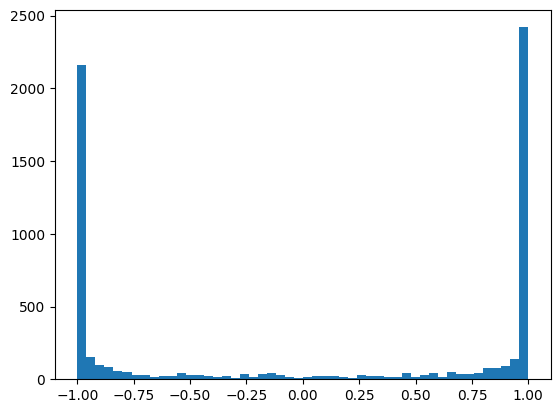

In [20]:
plt.hist(hidden.view(-1).tolist(),50)

(array([  1.,   0.,   0.,   1.,   2.,   3.,   6.,   9.,   8.,  17.,  12.,
         29.,  27.,  71.,  54.,  66.,  85., 153., 170., 215., 246., 239.,
        315., 317., 368., 365., 412., 394., 370., 330., 357., 290., 260.,
        271., 180., 197., 105., 143.,  82.,  80.,  38.,  27.,  23.,  19.,
         13.,  10.,   6.,  12.,   1.,   1.]),
 array([-21.68855476, -20.87570835, -20.06286194, -19.25001553,
        -18.43716911, -17.6243227 , -16.81147629, -15.99862988,
        -15.18578346, -14.37293705, -13.56009064, -12.74724422,
        -11.93439781, -11.1215514 , -10.30870499,  -9.49585857,
         -8.68301216,  -7.87016575,  -7.05731934,  -6.24447292,
         -5.43162651,  -4.6187801 ,  -3.80593369,  -2.99308727,
         -2.18024086,  -1.36739445,  -0.55454803,   0.25829838,
          1.07114479,   1.8839912 ,   2.69683762,   3.50968403,
          4.32253044,   5.13537685,   5.94822327,   6.76106968,
          7.57391609,   8.3867625 ,   9.19960892,  10.01245533,
         10.825301

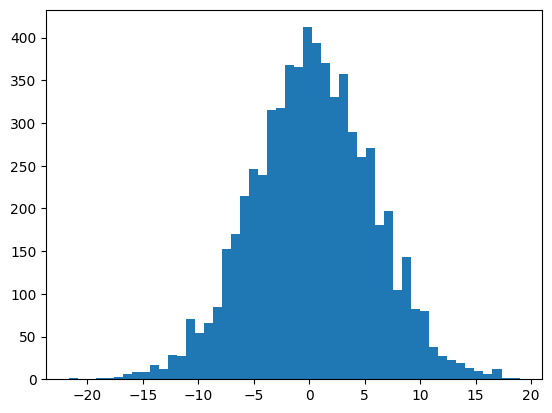

In [21]:
preact = input_lay @ W1 + b1
plt.hist(preact.view(-1).tolist(),50)

In [ ]:
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))